# Lab 4 - Zadanie

In [1]:
!pip install torch torchvision matplotlib

In [2]:
import copy
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)
print("Sprzęt:",
      torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

PyTorch: 2.14.1+cu130 | urządzenie: cuda
Sprzęt: Tesla T4


## 1. Dane

In [3]:
mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

full_ds = torchvision.datasets.CIFAR10(
    "./data", train=True, download=True, transform=tf)
test_ds = torchvision.datasets.CIFAR10(
    "./data", train=False, download=True, transform=tf)
classes = test_ds.classes

split_gen = torch.Generator().manual_seed(42)
perm = torch.randperm(len(full_ds), generator=split_gen)
train_ds = Subset(full_ds, perm[:45000].tolist())
val_ds = Subset(full_ds, perm[45000:].tolist())

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2)
print("Klasy:", classes)
print("Trening:", len(train_ds), "| Walidacja:", len(val_ds),
      "| Test:", len(test_ds))

100%|██████████| 170M/170M [10:39<00:00, 266kB/s]


Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Trening: 45000 | Walidacja: 5000 | Test: 10000


## 2. Modele

In [4]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(3 * 32 * 32, 512), nn.ReLU(),
        nn.Linear(512, 256), nn.ReLU(),
        nn.Linear(256, 10),
    )


def make_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(64 * 8 * 8, 256), nn.ReLU(),
        nn.Linear(256, 10),
    )


def count_params(model):
    return sum(p.numel() for p in model.parameters())


mlp, cnn = make_mlp(), make_cnn()
print(mlp)
print(cnn)
print("Parametry MLP:", count_params(mlp))
print("  w tym pierwsza warstwa:", count_params(mlp[1]))
print("Parametry CNN:", count_params(cnn))
print("  w tym warstwy splotowe:",
      sum(count_params(m) for m in cnn if isinstance(m, nn.Conv2d)))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=3072, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): ReLU()
  (5): Linear(in_features=256, out_features=10, bias=True)
)
Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4096, out_features=256, bias=True)
  (8): ReLU()
  (9): Linear(in_features=256, out_features=10, bias=True)
)
Parametry MLP: 1707274
  w tym pierwsza warstwa: 1573376
Parametry CNN: 1070794
  w tym warstwy splotowe: 19392


## 3. Trenowanie i ocena

In [5]:
EPOCHS = 15
LR = 1e-3


def evaluate(model, dl):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item()
            total += yb.numel()
    return correct / total


def train_model(make_model):
    torch.manual_seed(0)
    model = make_model().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"train_acc": [], "val_acc": []}
    best_acc, best_epoch, best_state = 0.0, 0, None
    train_time = 0.0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        correct = 0
        t0 = time.perf_counter()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            correct += (out.argmax(1) == yb).sum().item()
        train_time += time.perf_counter() - t0
        val_acc = evaluate(model, val_dl)
        hist["train_acc"].append(correct / len(train_ds))
        hist["val_acc"].append(val_acc)
        print(f"epoka {epoch:2d} | trening {hist['train_acc'][-1] * 100:.2f}%"
              f" | walidacja {val_acc * 100:.2f}%")
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, hist, best_epoch, train_time

## 4. Trening MLP i CNN

In [6]:
results = {}
for name, make_model in [("MLP", make_mlp), ("CNN", make_cnn)]:
    print(f"== {name} ==")
    results[name] = train_model(make_model)

== MLP ==
epoka  1 | trening 41.57% | walidacja 45.44%
epoka  2 | trening 49.06% | walidacja 49.42%
epoka  3 | trening 52.96% | walidacja 50.52%
epoka  4 | trening 56.32% | walidacja 52.02%
epoka  5 | trening 58.94% | walidacja 52.40%
epoka  6 | trening 61.67% | walidacja 52.80%
epoka  7 | trening 63.95% | walidacja 52.54%
epoka  8 | trening 66.49% | walidacja 51.82%
epoka  9 | trening 69.01% | walidacja 52.54%
epoka 10 | trening 71.04% | walidacja 51.86%
epoka 11 | trening 73.51% | walidacja 51.60%
epoka 12 | trening 75.75% | walidacja 52.76%
epoka 13 | trening 77.59% | walidacja 52.12%
epoka 14 | trening 79.36% | walidacja 51.08%
epoka 15 | trening 80.85% | walidacja 51.86%
== CNN ==
epoka  1 | trening 51.88% | walidacja 61.60%
epoka  2 | trening 66.15% | walidacja 68.12%
epoka  3 | trening 71.72% | walidacja 68.76%
epoka  4 | trening 75.73% | walidacja 70.44%
epoka  5 | trening 79.54% | walidacja 71.62%
epoka  6 | trening 83.32% | walidacja 72.00%
epoka  7 | trening 86.90% | walidac

## 5. Porównanie

In [7]:
rows = []
for name, (model, hist, best_epoch, train_time) in results.items():
    rows.append({
        "model": name,
        "liczba parametrów": count_params(model),
        "wybrana epoka": best_epoch,
        "accuracy walidacyjna [%]": round(max(hist["val_acc"]) * 100, 2),
        "accuracy testowa [%]": round(evaluate(model, test_dl) * 100, 2),
        "czas uczenia [s]": round(train_time, 1),
    })
pd.DataFrame(rows)

,model,liczba parametrów,wybrana epoka,accuracy walidacyjna [%],accuracy testowa [%],czas uczenia [s]
0,MLP,1707274,6,52.80,51.99,145.1
1,CNN,1070794,8,72.22,71.26,158.8


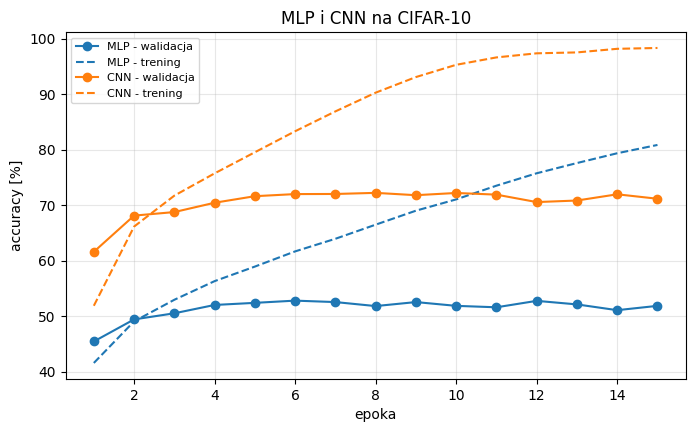

In [8]:
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(8, 4.5))
for (name, (_, hist, _, _)), color in zip(results.items(),
                                          ["tab:blue", "tab:orange"]):
    plt.plot(epochs, [a * 100 for a in hist["val_acc"]], "o-",
             color=color, label=f"{name} - walidacja")
    plt.plot(epochs, [a * 100 for a in hist["train_acc"]], "--",
             color=color, label=f"{name} - trening")
plt.xlabel("epoka")
plt.ylabel("accuracy [%]")
plt.title("MLP i CNN na CIFAR-10")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()